# 02 · Cleaning and EDA

Exploration and plots only; the logic is in `f1strat.clean`.

- `clean_laps` labels each lap with the first `exclude_reason` (or null if it is
  usable for the degradation model) and adds `gap_ahead_s` and `dirty_air`.
- `pit_loss_with_references` gives the median green-flag pit lane loss per
  circuit. Monaco (mixed conditions in 2022, and a case study) takes it from
  the 2021 race; Imola, Singapore and Suzuka are marked not needed.

`Rainfall` is not an exclude reason; it stays as a column for Phase 3.

Raw lap times may stay flat or fall as tyre age rises because fuel burns off.
That is expected and is separated out in Phase 3, so it is not corrected here.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

from f1strat import figure_data as fd
from f1strat import figures as F
from f1strat.clean import clean_laps, pit_loss
from f1strat.data import load_season

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Figures are drawn by f1strat.figures, the same functions `pitwall figures` uses to
# write reports/figures from data/figures; here they are only shown.

laps = load_season(2022)
race = load_season(2022, table="race")
cleaned = clean_laps(laps)
clean = cleaned[cleaned["exclude_reason"].isna()].assign(
    lap_s=lambda d: d["LapTime"].dt.total_seconds()
)
print(f"{len(cleaned):,} laps, {len(clean):,} clean ({len(clean) / len(cleaned):.0%})")
print(f"dirty air on {clean['dirty_air'].mean():.0%} of clean laps")

23,577 laps, 15,677 clean (66%)
dirty air on 21% of clean laps


## Clean lap time vs tyre age: Bahrain, Spain, Hungary

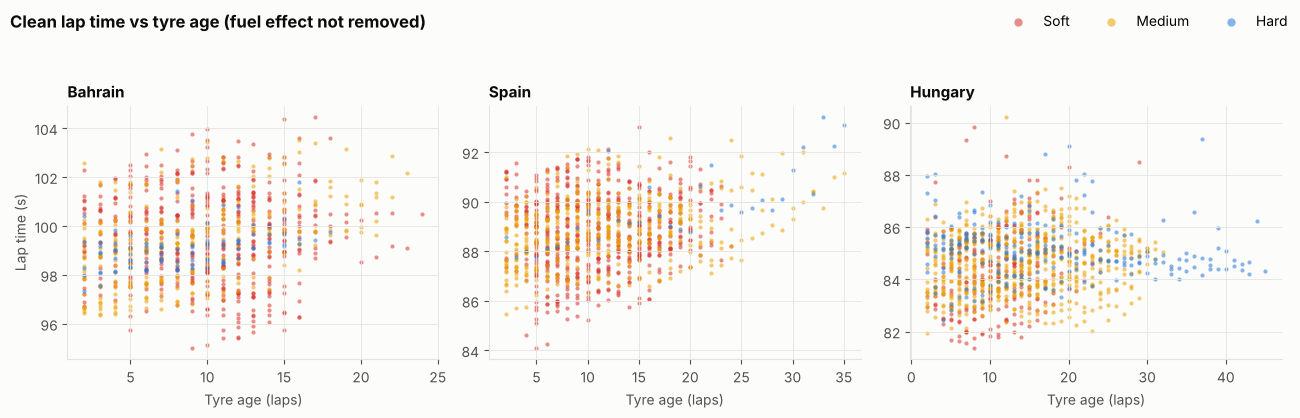

In [2]:
F.plot_deg_three_races(clean, show=True);

## All 22 races, same view

A sanity check for incoherent stints or wild outliers. Each panel has its own
y-axis.

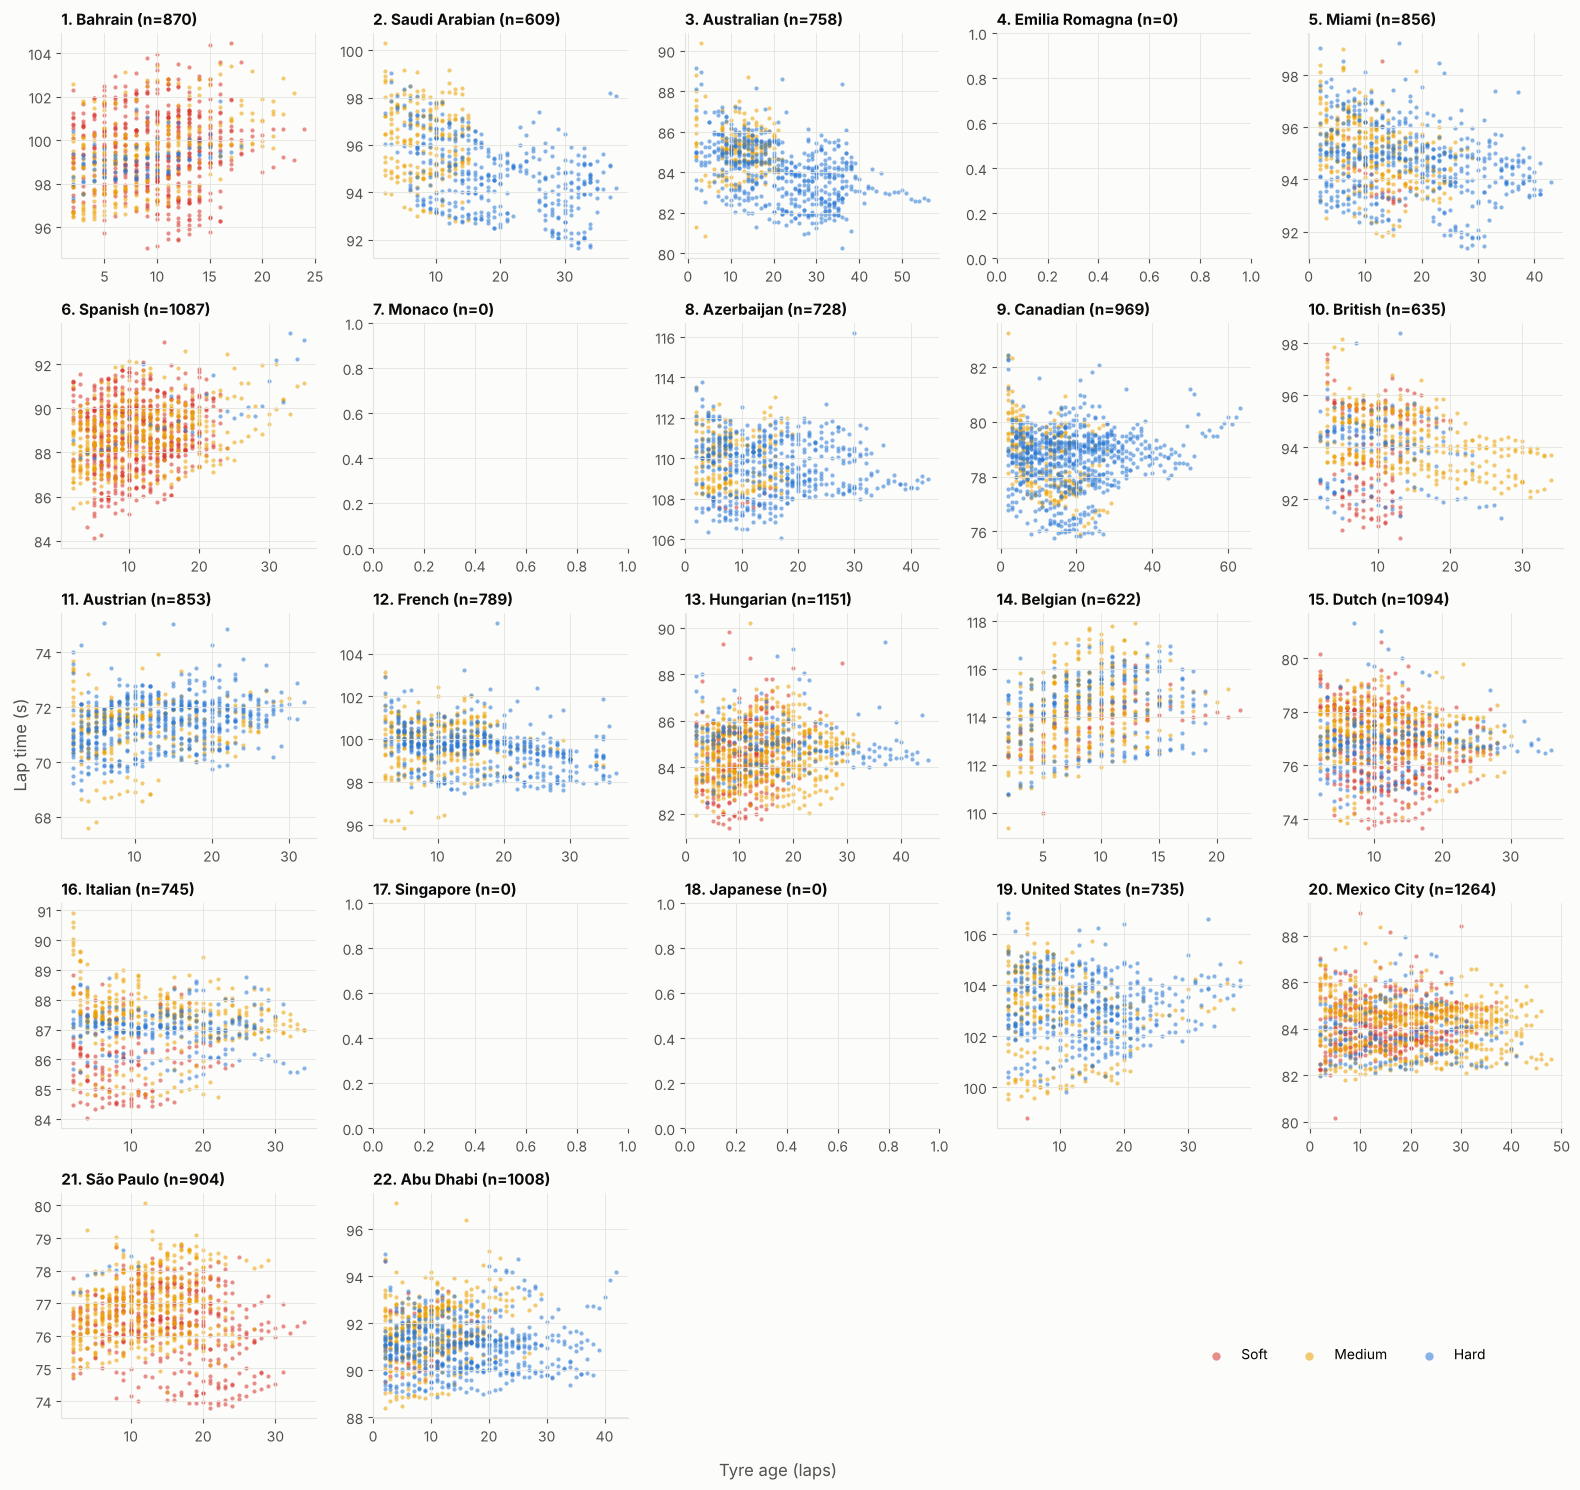

In [3]:
rounds = race.groupby("RoundNumber")["EventName"].first()
F.plot_deg_all_races(clean, rounds, show=True);

## Laps per exclude reason per race

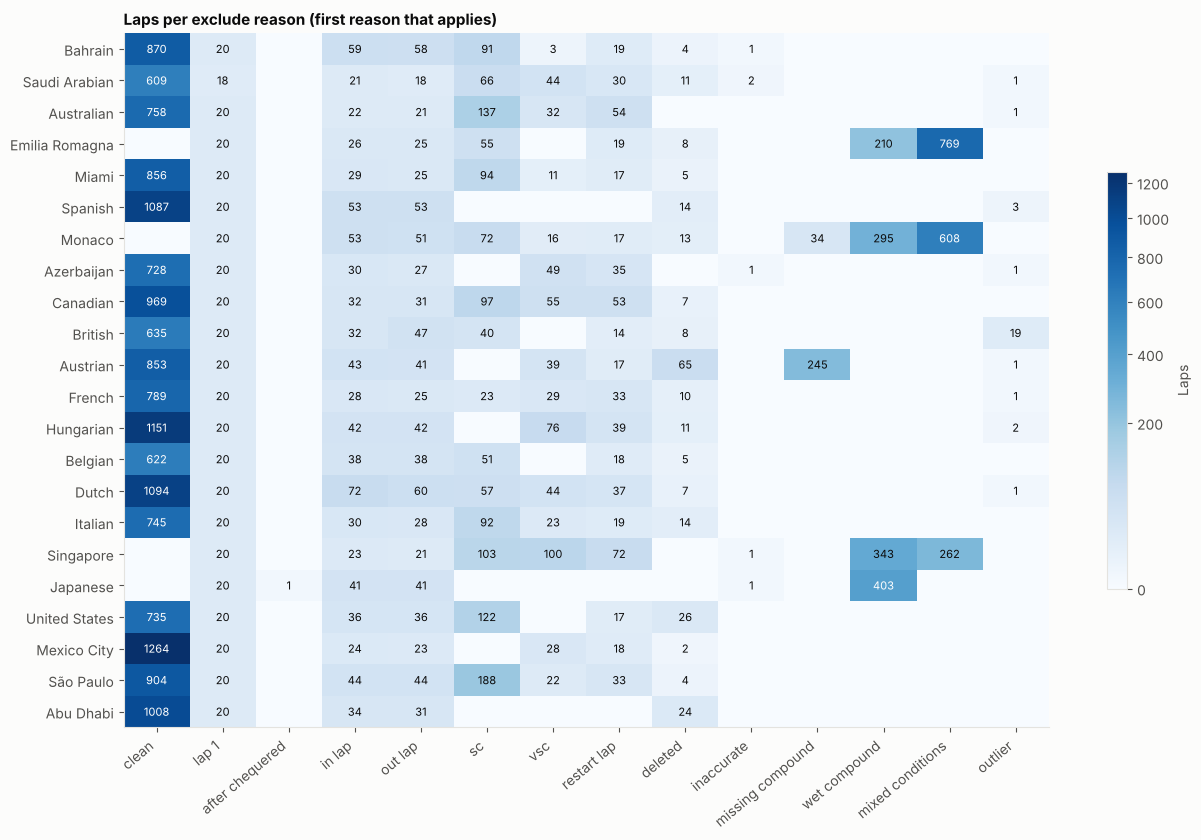

reason,after_chequered,clean,deleted,in_lap,inaccurate,lap_1,missing_compound,mixed_conditions,out_lap,outlier,restart_lap,sc,vsc,wet_compound
EventName,,,,,,,,,,,,,,
Bahrain Grand Prix,0,870,4,59,1,20,0,0,58,0,19,91,3,0
Saudi Arabian Grand Prix,0,609,11,21,2,18,0,0,18,1,30,66,44,0
Australian Grand Prix,0,758,0,22,0,20,0,0,21,1,54,137,32,0
Emilia Romagna Grand Prix,0,0,8,26,0,20,0,769,25,0,19,55,0,210
Miami Grand Prix,0,856,5,29,0,20,0,0,25,0,17,94,11,0
Spanish Grand Prix,0,1087,14,53,0,20,0,0,53,3,0,0,0,0
Monaco Grand Prix,0,0,13,53,0,20,34,608,51,0,17,72,16,295
Azerbaijan Grand Prix,0,728,0,30,1,20,0,0,27,1,35,0,49,0
Canadian Grand Prix,0,969,7,32,0,20,0,0,31,0,53,97,55,0


In [4]:
excl = fd.exclude_reasons_table()
F.plot_exclude_reasons(excl, show=True)
excl.pivot(index="EventName", columns="reason", values="laps").loc[rounds.values]

## Green-flag pit lane loss per circuit

Per stop: (in lap + out lap) minus 2 × the driver's median clean lap. Dot is
the median over green-flag stops; bar is the interquartile range. Hollow dots
come from a reference season (label shows the year); circuits marked not
needed are listed below.

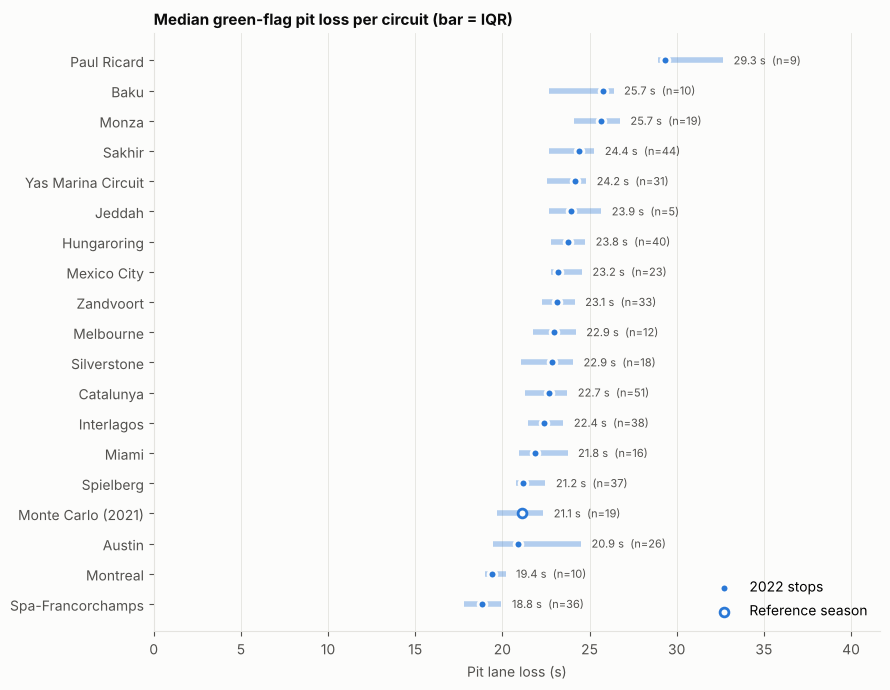

not needed (mixed conditions, not a case study): ['Imola', 'Singapore', 'Suzuka']


,RoundNumber,EventName,Circuit,pit_loss_s,q25_s,q75_s,n_stops,source_year,pit_loss_status
0,1,Bahrain Grand Prix,Sakhir,24.3990,22.66075,25.27875,44,2022,own_race
1,2,Saudi Arabian Grand Prix,Jeddah,23.9370,22.70000,25.67400,5,2022,own_race
2,3,Australian Grand Prix,Melbourne,22.9490,21.76300,24.21125,12,2022,own_race
3,4,Emilia Romagna Grand Prix,Imola,NaN,NaN,NaN,0,<NA>,not_needed
4,5,Miami Grand Prix,Miami,21.8450,20.93550,23.73875,16,2022,own_race
5,6,Spanish Grand Prix,Catalunya,22.6630,21.28450,23.72650,51,2022,own_race
6,7,Monaco Grand Prix,Monte Carlo,21.1220,19.70900,22.34600,19,2021,reference
7,8,Azerbaijan Grand Prix,Baku,25.7480,22.68475,26.37875,10,2022,own_race
8,9,Canadian Grand Prix,Montreal,19.3895,19.02150,20.18325,10,2022,own_race
9,10,British Grand Prix,Silverstone,22.8670,21.08175,24.05475,18,2022,own_race


In [5]:
pit = pd.read_parquet("../data/processed/2022/pit_loss.parquet")
own = pit_loss(cleaned, race)
saved_own = pit[pit["source_year"] == 2022]
assert np.allclose(saved_own["pit_loss_s"], own["pit_loss_s"]), "saved table is stale"

F.plot_pit_loss(pit, show=True)
not_needed = pit.loc[pit["pit_loss_status"] == "not_needed", "Circuit"].tolist()
print("not needed (mixed conditions, not a case study):", not_needed)
pit